# Assignment MMB

---

## Important Dates
- Homework release: Tue 22 Sep 2026
- **Homework due:** Mon 30 Nov 2026, 11:59 AM

---

This notebook is not graded, the markdown cells should help you create an error component model, step by step.

## Some rules
1. You are allowed to use any built-in Python library that comes with Anaconda. If you want to use an external library, you may do so, but must justify your choice.

2. Make sure you use the `data` folder provided in the repository in read-only mode. (Or alternatively, be sure you don’t change any of the files.) One should be able to reproduce your results using the original data files.

3. Be sure to provide a concise textual description of your thought process, the assumptions you made, the solution you implemented, and explanations for your answers.

4. Several questions ask to comment and analyze the results. Make sure to provide a clear interpretation of the results. A few lines of text should be enough to explain your reasoning and the implications of the results.

5. Please write all your comments in **English**, and use meaningful variable names in your code. 

6. Make sure to print results and/or dataframes that confirm you have properly addressed the task.


In [1]:
import biogeme.version as ver
print(ver.get_text())
# This assignment uses Biogeme 3.3.5.

biogeme 3.3.5 [2026-11-25]
Home page: http://biogeme.epfl.ch
Submit questions to https://groups.google.com/d/forum/biogeme
Michel Bierlaire, Transport and Mobility Laboratory, Ecole Polytechnique Fédérale de Lausanne (EPFL)



In [2]:
import numpy as np
import pandas as pd
import biogeme.database as db
import biogeme.biogeme as bio
from biogeme.models import logit, loglogit, lognested, logcnl
from biogeme.nests import OneNestForNestedLogit, NestsForNestedLogit, OneNestForCrossNestedLogit, NestsForCrossNestedLogit
from biogeme.expressions import Beta, Variable, log, exp, RandomVariable, IntegrateNormal, Draws, MonteCarlo, Derive
from biogeme.results_processing import compile_estimation_results, get_pandas_estimated_parameters
from biogeme.tools import likelihood_ratio_test
from datetime import datetime as dt
print(f'Date: {dt.now().strftime("%Y-%m-%d %H:%M:%S")}')

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Date: 2026-11-25 19:40:57


/home/kamil/dev/london-mode-choice/.venv/lib/python3.14/site-packages/tqdm_joblib/__init__.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


# Model 0 

---

Start with a model specification that includes alternative specific constants, and cost and travel time of the different alternatives associated with generic parameters. Report both the specification (i.e., the utility functions) and the estimation results (parameter values, t-tests or p-values, null and final log likelihoods).  

Calculate the total public transport duration as the sum of `dur_pt_access`, `dur_pt_rail`, `dur_pt_bus`, and `dur_pt_int`. Similarly, calculate the total driving cost as the sum of `cost_driving_fuel` and `cost_driving_ccharge`.

1. Comment on the estimation output (sign and significance of all parameters, and goodness of fit indices).  

---

**0.1. – Preparing the data**  
- Load your assigned LPMC dataset.
- Compute `total_pt_duration = dur_pt_access + dur_pt_rail + dur_pt_bus + dur_pt_int`.
- Compute `total_driving_cost = cost_driving_fuel + cost_driving_ccharge`.
- All individuals and all alternatives should be kept.

In [3]:
# Load the assigned data file (group 09). The data folder is only read, never modified.
df = pd.read_table('../data/lpmc09.dat')

# Create the two aggregate attributes requested in the question.
df['total_pt_duration'] = df['dur_pt_access'] + df['dur_pt_rail'] + df['dur_pt_bus'] + df['dur_pt_int']
df['total_driving_cost'] = df['cost_driving_fuel'] + df['cost_driving_ccharge']

# Create a Biogeme database from your dataframe.
database = db.Database('lpmc09', df)

print(f'Number of observations: {len(df)}')
display(df['travel_mode'].value_counts().sort_index().rename({1: 'walk', 2: 'cycle', 3: 'pt', 4: 'car'})
        .to_frame('count').assign(share=lambda x: x['count'] / x['count'].sum()))
display(df[['dur_walking', 'dur_cycling', 'total_pt_duration', 'dur_driving',
            'cost_transit', 'total_driving_cost', 'age', 'female']].describe().T)

Number of observations: 5000


,count,share
travel_mode,,
walk,815,0.1630
cycle,230,0.0460
pt,1773,0.3546
car,2182,0.4364


,count,mean,std,min,25%,50%,75%,max
dur_walking,5000.0,1.305683,1.248600,0.029444,0.379583,0.849444,1.856111,9.278333
dur_cycling,5000.0,0.418769,0.391812,0.006111,0.126667,0.277500,0.595000,2.660278
total_pt_duration,5000.0,0.504950,0.333123,0.016944,0.237431,0.429028,0.713611,2.363889
dur_driving,5000.0,0.322242,0.279509,0.009167,0.113889,0.225833,0.446736,1.855278
cost_transit,5000.0,1.909906,1.633134,0.000000,1.500000,1.500000,3.000000,13.490000
total_driving_cost,5000.0,2.339970,3.871111,0.030000,0.310000,0.710000,1.720000,16.600000
age,5000.0,45.099400,16.271179,19.000000,32.000000,43.000000,56.000000,94.000000
female,5000.0,0.050000,0.217967,0.000000,0.000000,0.000000,0.000000,1.000000


**0.2. – Model specification**  
- Define a model with:
  - Alternative-specific constants (ASCs),
  - A generic parameter for total cost,
  - A generic parameter for total travel time.
- Use the same parameter values across alternatives (generic parameters).


In [4]:
# Define a Variable object for every data column used in the utilities.
# Durations are in hours, costs in GBP.
travel_mode = Variable('travel_mode')
dur_walking = Variable('dur_walking')
dur_cycling = Variable('dur_cycling')
total_pt_duration = Variable('total_pt_duration')
dur_driving = Variable('dur_driving')
cost_transit = Variable('cost_transit')
total_driving_cost = Variable('total_driving_cost')
age = Variable('age')

In [5]:
# Define the choice variable, generic time and cost coefficients, and ASCs.
# Walking is the reference alternative: its ASC is not defined (fixed to 0) for identification.
asc_cycle = Beta('asc_cycle', 0, None, None, 0)
asc_pt = Beta('asc_pt', 0, None, None, 0)
asc_car = Beta('asc_car', 0, None, None, 0)

b_time = Beta('b_time', 0, None, None, 0)
b_cost = Beta('b_cost', 0, None, None, 0)

# All alternatives are available to all individuals.
availability = {1: 1, 2: 1, 3: 1, 4: 1}

In [6]:
# Write one utility for each alternative, then collect them in V_0.
# Walking and cycling have no monetary cost.
V_walk_0 = b_time * dur_walking
V_cycle_0 = asc_cycle + b_time * dur_cycling
V_pt_0 = asc_pt + b_time * total_pt_duration + b_cost * cost_transit
V_car_0 = asc_car + b_time * dur_driving + b_cost * total_driving_cost

V_0 = {
    1: V_walk_0,
    2: V_cycle_0,
    3: V_pt_0,
    4: V_car_0
}

**Specification of Model 0** (walk is the reference alternative):

$$
\begin{aligned}
V_{walk} &= \beta_{time}\, T_{walk} \\
V_{cycle} &= ASC_{cycle} + \beta_{time}\, T_{cycle} \\
V_{pt} &= ASC_{pt} + \beta_{time}\, T_{pt} + \beta_{cost}\, C_{pt} \\
V_{car} &= ASC_{car} + \beta_{time}\, T_{car} + \beta_{cost}\, C_{car}
\end{aligned}
$$

where $T$ are travel times in hours (with $T_{pt}$ = `total_pt_duration`), $C_{pt}$ = `cost_transit` and $C_{car}$ = `total_driving_cost` (in GBP).

**0.3. – Estimation of the parameters**  
- Estimate the model using Biogeme.
- Report:
  - Parameter estimates,
  - t-statistics or p-values,
  - Null and final log-likelihoods.

In [7]:
# Build the log-likelihood with loglogit, create a BIOGEME object, and estimate Model 0.
# Log-likelihood function:
# - util: dictionary with the utilities,
# - av: dictionary of availability (all alternatives available),
# - i: observed choice in the database.
# The helper is reused for every logit model below (HTML/YAML/iteration files are not needed here).
def estimate_logit(utilities, model_name):
    logprob = loglogit(util=utilities, av=availability, i=travel_mode)
    biogeme_model = bio.BIOGEME(database, logprob, generate_html=False, generate_yaml=False, save_iterations=False)
    biogeme_model.model_name = model_name
    return biogeme_model.estimate()

# Estimate the model
results_0 = estimate_logit(V_0, 'model_0')

In [8]:
# In Biogeme 3.3.5, the parameter tables are named: 
param_0 = get_pandas_estimated_parameters(estimation_results=results_0)
display(param_0['Estimated parameters'])

# Keep every estimated model in this dictionary for later comparisons.
all_results = {}
all_results['model_0'] = results_0

,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time,-4.973198,0.185989,-26.739260,0.0
1,asc_cycle,-3.274990,0.091985,-35.603436,0.0
2,asc_pt,-0.520112,0.054626,-9.521258,0.0
3,b_cost,-0.149278,0.011315,-13.193179,0.0
4,asc_car,-1.176688,0.078355,-15.017310,0.0


In [9]:
# In order to print general statistics such as the number of estimated parameters, the final log likelihood or the final gradient norm:

general_stats = results_0.get_general_statistics()
display(general_stats)

# or more synthetic
print(results_0.short_summary())

{'Number of estimated parameters': '5',
 'Sample size': '5000',
 'Excluded observations': '0',
 'Init log likelihood': '-6931.472',
 'Final log likelihood': '-4710.09',
 'Likelihood ratio test for the init. model': '4442.763',
 'Rho-square for the init. model': '0.32',
 'Rho-square-bar for the init. model': '0.32',
 'Akaike Information Criterion': '9430.181',
 'Bayesian Information Criterion': '9462.767',
 'Final gradient norm': '7.9073E-04',
 'Bootstrapping time': 'None'}

Results for model model_0
Nbr of parameters:		5
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4710.09
Akaike Information Criterion:	9430.181
Bayesian Information Criterion:	9462.767



**0.4. – Interpretation of the results**  
- Discuss the sign of each parameter and whether it aligns with expected behavior.
- Comment on the statistical significance of the coefficients.
- Evaluate the overall model fit.

<div class="alert alert-info">
  Your comments should be concise and to the point, focusing on the most relevant aspects of the model and its results.
</div>

**Comments on Model 0**

- **Signs.** Both $\beta_{time}$ and $\beta_{cost}$ are negative, as expected: longer and more expensive trips reduce the utility of a mode. Their ratio gives an implied value of time of about 33 GBP/hour. That is high, but it is a single average over very different modes and travellers.
- **Constants.** All three ASCs are negative relative to walking, so for the same time and cost the sample has an unexplained preference for walking. This is driven mostly by cycling ($ASC_{cycle} \approx -3.3$, only 4.6% of trips are by bike). The negative $ASC_{car}$ captures unobserved factors such as parking or not having a car or licence, none of which are in the model yet.
- **Significance.** Every parameter is highly significant ($|t| > 9$, p-values ≈ 0).
- **Fit.** The final log-likelihood is about −4710, against a null log-likelihood of $5000 \ln(1/4) \approx -6931$. This gives $\rho^2 \approx 0.32$, a reasonable fit for a first specification with 5 parameters.

# Model 1 

---

Using Model 0 as the base model, include alternative-specific parameters (i.e., different parameters per alternative) for one of the attributes of Model 0. Report both the specification and the estimation results (parameter values, t-tests or p-values, null and final log likelihoods).

1. State the behavioral assumption of defining alternative-specific parameters in this specific situation.  
2. Comment on the estimation output (as defined previously, including any changes from the previous model).  

3. Compare Model 0 and Model 1 with an appropriate statistical test. Justify your choice of test. State the null hypothesis and the result of the test. Denote the preferred model as $\text{Model}_\text{pref}$.  

---

**1.1. – Model modification**  
- Start from Model 0 and choose **one attribute** (e.g., cost or time).
- Replace the generic coefficient for that attribute with **alternative-specific parameters**.
  - For example: instead of one $\beta_{\text{time}}$, define $\beta_{\text{time, car}}$...


In [10]:
# Choose ONE attribute from Model 0 (here: travel time).
# Replace its generic coefficient with alternative-specific coefficients.
# Model 1 is nested in Model 0 (Model 0 is obtained with b_time_walk = b_time_cycle = b_time_pt = b_time_car).
b_time_walk = Beta('b_time_walk', 0, None, None, 0)
b_time_cycle = Beta('b_time_cycle', 0, None, None, 0)
b_time_pt = Beta('b_time_pt', 0, None, None, 0)
b_time_car = Beta('b_time_car', 0, None, None, 0)

V_walk_1 = b_time_walk * dur_walking
V_cycle_1 = asc_cycle + b_time_cycle * dur_cycling
V_pt_1 = asc_pt + b_time_pt * total_pt_duration + b_cost * cost_transit
V_car_1 = asc_car + b_time_car * dur_driving + b_cost * total_driving_cost

V_1 = {
    1: V_walk_1,
    2: V_cycle_1,
    3: V_pt_1,
    4: V_car_1
}

**1.2. – Behavioral interpretation**  
- Clearly state the behavioral assumption behind using different coefficients across alternatives.
  - Why might the sensitivity to that attribute differ by alternative?


**Specification of Model 1:** same as Model 0, but with alternative-specific time coefficients $\beta_{time,walk}$, $\beta_{time,cycle}$, $\beta_{time,pt}$ and $\beta_{time,car}$.

**Behavioural assumption.** One hour spent travelling does not cause the same disutility on every mode. Walking and cycling take physical effort and expose travellers to the weather. Driving involves congestion stress and the effort of driving. In public transport, travel time can partly be used for other activities (reading, phone), so it should be less onerous per hour. The marginal utility of time is therefore allowed to differ across modes, while the marginal utility of money (cost) stays generic, since a pound has the same value whatever mode it is spent on.

**1.3. – Estimation and output analysis**  
- Estimate the updated model.
- Report and interpret:
  - Parameter estimates and their signs,
  - Statistical significance (t-stats or p-values),
  - Null and final log-likelihoods,
  - Any noticeable changes compared to Model 0.


In [11]:
results_1 = estimate_logit(V_1, 'model_1')
print(results_1.short_summary())
display(get_pandas_estimated_parameters(estimation_results=results_1)['Estimated parameters'])

Results for model model_1
Nbr of parameters:		8
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4416.83
Akaike Information Criterion:	8849.659
Bayesian Information Criterion:	8901.797



,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time_walk,-7.431550,0.398507,-18.648476,0.0
1,asc_cycle,-4.012184,0.174002,-23.058209,0.0
2,b_time_cycle,-5.033347,0.347192,-14.497313,0.0
3,asc_pt,-2.249014,0.137906,-16.308287,0.0
4,b_time_pt,-3.095653,0.231108,-13.394823,0.0
5,b_cost,-0.137408,0.012300,-11.170949,0.0
6,asc_car,-1.729702,0.136177,-12.701817,0.0
7,b_time_car,-5.679782,0.344189,-16.501914,0.0


In [12]:
# Add Model 1 before producing a comparison table.
all_results['model_1'] = results_1

comparison_table, _ = compile_estimation_results(all_results)
display(comparison_table)

,model_0,model_1
Number of estimated parameters,5,8
Sample size,5000,5000
Final log likelihood,-4710.09,-4416.83
Akaike Information Criterion,9430.181,8849.659
Bayesian Information Criterion,9462.767,8901.797
b_time (t-test),-4.97 (-26.7),
asc_cycle (t-test),-3.27 (-35.6),-4.01 (-23.1)
asc_pt (t-test),-0.52 (-9.52),-2.25 (-16.3)
b_cost (t-test),-0.149 (-13.2),-0.137 (-11.2)
asc_car (t-test),-1.18 (-15),-1.73 (-12.7)


**Comments on Model 1**

- **Signs and significance.** All four time coefficients are negative and highly significant. The cost coefficient barely changes (−0.149 → −0.137) and stays significant.
- **Ranking of time sensitivities.** In absolute value: walk (−7.4) > car (−5.7) > cycle (−5.0) > PT (−3.1). As expected, PT time is the least onerous and walking time the most. The implied values of time are about 22.5 GBP/h for PT and 41 GBP/h for car. Time spent driving is perceived as more onerous than time in PT, which can partly be used for other activities.
- **Constants.** The ASCs of PT and car become more negative. Since PT time is now valued less, a larger negative constant is needed to reproduce the observed PT share.
- **Fit.** The log-likelihood improves from −4710.1 to −4416.8 with 3 extra parameters ($\rho^2$ rises from about 0.32 to about 0.36).

**1.4. – Model comparison and selection**  
- Perform a likelihood ratio test (or another appropriate test) to compare Model 0 and Model 1.
- Clearly state:
  - The null hypothesis,
  - The degrees of freedom used,
  - The value of the test statistic and p-value,
  - The conclusion: which model is preferred ($\text{Model}_\text{pref}$)?

In [13]:
# Model 0 is the restricted model and Model 1 is the unrestricted model.
# H0: b_time_walk = b_time_cycle = b_time_pt = b_time_car (3 linear restrictions).
# The models are nested, so the likelihood ratio test applies:
# -2 (LL_0 - LL_1) ~ chi2 with (K_1 - K_0) degrees of freedom under H0.

In [14]:
# Extract log-likelihoods and number of estimated parameters
logL_0 = all_results['model_0'].final_loglikelihood
nparam_0 = all_results['model_0'].number_of_parameters # or number_of_free_parameters


logL_1 = all_results['model_1'].final_loglikelihood
nparam_1 = all_results['model_1'].number_of_parameters

# Run likelihood ratio test: model_0 is restricted, model_1 is unrestricted
lr_result = likelihood_ratio_test(
    model1=(logL_0, nparam_0),
    model2=(logL_1, nparam_1),
    significance_level=0.05
)
display(lr_result)

# Display results
print(f"Null hypothesis: b_time_walk = b_time_cycle = b_time_pt = b_time_car (Model 0 is sufficient)")
print(f"Degrees of freedom: {nparam_1 - nparam_0}")
print(f"Log-likelihood Model 0: {logL_0:.2f}")
print(f"Log-likelihood Model 1: {logL_1:.2f}")
print(f"Likelihood Ratio Statistic: {lr_result.statistic:.2f}")
print(f"Chi-squared Threshold (95%): {lr_result.threshold:.2f}")
print(f"{lr_result.message}")

LRTuple(message='H0 can be rejected at level 5.0%', statistic=586.5217158370579, threshold=np.float64(7.814727903251179))

Null hypothesis: b_time_walk = b_time_cycle = b_time_pt = b_time_car (Model 0 is sufficient)
Degrees of freedom: 3
Log-likelihood Model 0: -4710.09
Log-likelihood Model 1: -4416.83
Likelihood Ratio Statistic: 586.52
Chi-squared Threshold (95%): 7.81
H0 can be rejected at level 5.0%


**Likelihood ratio test.** The test is valid because Model 0 is a restricted version of Model 1: it imposes 3 linear equality restrictions on the time coefficients.

- $H_0$: $\beta_{time,walk} = \beta_{time,cycle} = \beta_{time,pt} = \beta_{time,car}$.
- Statistic: $-2(\mathcal{L}_0 - \mathcal{L}_1) = -2(-4710.1 + 4416.8) \approx 586.5$, compared with $\chi^2_{0.95,3} = 7.81$.
- $H_0$ is clearly rejected, so the time sensitivities differ across modes.

$\Rightarrow$ $\text{Model}_\text{pref}$ = **Model 1**.

# Model 2 

---

Using $\text{Model}_\text{pref}$ as the base model, choose a socioeconomic characteristic and define two model specifications. In the first specification, interact the socioeconomic characteristic with an alternative-specific constant. In the second specification, interact it with an alternative attribute. Report both the specification and the estimation results (parameter values, t-tests or p-values, null and final log likelihoods).

1. State the behavioral assumptions in this specific situation and how this specification explains behavior differently from $\text{Model}_\text{pref}$.  
2. Comment on the estimation output (as defined previously).  

3. Compare $\text{Model}_\text{pref}$ and **Model 2** (both specifications) with an appropriate statistical test. Justify your choice of test. State the null hypothesis and the result of the test. Denote the preferred model as $\text{Model}_\text{pref}$.  

---

**2.0. – Model extension: interaction with socioeconomic variable**  
- Choose a socioeconomic characteristic from the dataset (e.g., age, gender).
- Create **two different model specifications**:
  - One where the characteristic interacts with an **alternative-specific constant**.
  - One where it interacts with an **attribute** (e.g., cost or time).


In [15]:
# Socioeconomic characteristic: age.
# Gender is not used because only 5% of the trips in our sample are made by women.
# Age is centred at 45 (close to the sample mean) and measured in decades, so the ASCs and time
# coefficients of Model_pref keep their interpretation for a 45-year-old traveller.
age_centred = (age - 45) / 10

# --- Specification 2a: age interacting with the alternative-specific constants ---
b_age_cycle = Beta('b_age_cycle', 0, None, None, 0)
b_age_pt = Beta('b_age_pt', 0, None, None, 0)
b_age_car = Beta('b_age_car', 0, None, None, 0)

V_2a = {
    1: V_walk_1,
    2: V_cycle_1 + b_age_cycle * age_centred,
    3: V_pt_1 + b_age_pt * age_centred,
    4: V_car_1 + b_age_car * age_centred
}

# --- Specification 2b: age interacting with the travel time attribute ---
# A generic shift of every time coefficient: beta_time,i(age) = beta_time,i + b_time_age * (age - 45) / 10
b_time_age = Beta('b_time_age', 0, None, None, 0)

V_2b = {
    1: V_walk_1 + b_time_age * age_centred * dur_walking,
    2: V_cycle_1 + b_time_age * age_centred * dur_cycling,
    3: V_pt_1 + b_time_age * age_centred * total_pt_duration,
    4: V_car_1 + b_time_age * age_centred * dur_driving
}

results_2a = estimate_logit(V_2a, 'model_2a_age_asc')
results_2b = estimate_logit(V_2b, 'model_2b_age_time')

for results in [results_2a, results_2b]:
    print(results.short_summary())
    display(get_pandas_estimated_parameters(estimation_results=results)['Estimated parameters'])

Results for model model_2a_age_asc
Nbr of parameters:		11
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4370.098
Akaike Information Criterion:	8762.196
Bayesian Information Criterion:	8833.885



,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time_walk,-7.561186,0.408705,-18.500363,0.000000
1,asc_cycle,-4.060624,0.178408,-22.760264,0.000000
2,b_time_cycle,-5.119478,0.352789,-14.511444,0.000000
3,b_age_cycle,0.025945,0.050397,0.514813,0.606684
4,asc_pt,-2.311543,0.141279,-16.361546,0.000000
5,b_time_pt,-3.049138,0.228810,-13.326073,0.000000
6,b_cost,-0.142598,0.012865,-11.084525,0.000000
7,b_age_pt,0.130966,0.032454,4.035469,0.000054
8,asc_car,-1.851627,0.141449,-13.090440,0.000000
9,b_time_car,-5.452130,0.343680,-15.863979,0.000000


Results for model model_2b_age_time
Nbr of parameters:		9
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4363.731
Akaike Information Criterion:	8745.462
Bayesian Information Criterion:	8804.116



,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time_walk,-7.716545,0.392157,-19.677168,0.0
1,b_time_age,-0.755823,0.079963,-9.452176,0.0
2,asc_cycle,-4.088950,0.171542,-23.836476,0.0
3,b_time_cycle,-5.212262,0.338527,-15.396893,0.0
4,asc_pt,-2.281193,0.134878,-16.912957,0.0
5,b_time_pt,-3.261425,0.229962,-14.182458,0.0
6,b_cost,-0.150468,0.013274,-11.335204,0.0
7,asc_car,-1.836888,0.134550,-13.652104,0.0
8,b_time_car,-5.710503,0.338947,-16.847754,0.0


**2.1. – Behavioral interpretation**  
- Explain what each interaction is capturing in terms of behavior.
- How does this differ from $\text{Model}_\text{pref}$?
- What new insight does each interaction provide?

**Specifications** (with $a_n = (\text{age}_n - 45)/10$, starting from Model 1):

- **Model 2a (age × ASC):** $V_i = V_i^{(1)} + \beta_{age,i}\, a_n$ for $i \in \{cycle, pt, car\}$ (walk stays the reference).
- **Model 2b (age × time):** $V_i = V_i^{(1)} + \beta_{time,age}\, a_n\, T_i$ for all $i$, i.e. $\beta_{time,i}(a_n) = \beta_{time,i} + \beta_{time,age}\, a_n$.

**Behavioural assumptions.**

- **2a.** Age shifts the intrinsic preference for each mode independently of its level of service. Older travellers may value the comfort of car or PT, may be less willing to make physical effort, and are more likely to own a car. In Model 1 every traveller had the same constants. Here the unobserved "taste" for a mode varies systematically with age.
- **2b.** Age changes the sensitivity to travel time. A negative $\beta_{time,age}$ means older travellers find each extra minute of travel more burdensome (fatigue, discomfort), especially for long active trips. In Model 1 the time sensitivity was the same for everybody. Here it is heterogeneous across the population, which also makes the value of time depend on age.

**2.2. – Estimation and result interpretation**  
- Estimate both specifications of Model 2.
- For each:
  - Report parameter estimates, t-stats or p-values.
  - Compare null and final log-likelihoods.
  - Comment on changes in signs, magnitudes, or statistical significance compared to $\text{Model}_\text{pref}$.


In [16]:
# Store your estimated Model 2 results before comparing models.
all_results['model_2a_age_asc'] = results_2a
all_results['model_2b_age_time'] = results_2b

comparison_table, _ = compile_estimation_results(all_results)
display(comparison_table)

,model_0,model_1,model_2a_age_asc,model_2b_age_time
Number of estimated parameters,5,8,11,9
Sample size,5000,5000,5000,5000
Final log likelihood,-4710.09,-4416.83,-4370.098,-4363.731
Akaike Information Criterion,9430.181,8849.659,8762.196,8745.462
Bayesian Information Criterion,9462.767,8901.797,8833.885,8804.116
b_time (t-test),-4.97 (-26.7),,,
asc_cycle (t-test),-3.27 (-35.6),-4.01 (-23.1),-4.06 (-22.8),-4.09 (-23.8)
asc_pt (t-test),-0.52 (-9.52),-2.25 (-16.3),-2.31 (-16.4),-2.28 (-16.9)
b_cost (t-test),-0.149 (-13.2),-0.137 (-11.2),-0.143 (-11.1),-0.15 (-11.3)
asc_car (t-test),-1.18 (-15),-1.73 (-12.7),-1.85 (-13.1),-1.84 (-13.7)


**Comments on Model 2**

- **Model 2a.** $\beta_{age,car} \approx 0.25$ and $\beta_{age,pt} \approx 0.13$ are positive and significant. Every 10 years of age increase the preference for car (and, less strongly, PT) relative to walking. $\beta_{age,cycle}$ is not significant (t ≈ 0.5), which is not surprising with only 230 cycling trips. The other parameters keep their sign and significance and change only slightly in magnitude. The log-likelihood goes from −4416.8 to −4370.1 with 3 extra parameters.
- **Model 2b.** $\beta_{time,age} \approx -0.76$ (t ≈ −9.5): the disutility of time grows with age. For example, the walking time coefficient goes from about −7.7 at age 45 to about −9.2 at age 65. The other parameters remain stable and significant. The log-likelihood goes from −4416.8 to −4363.7 with only 1 extra parameter.
- **Both specifications** are behaviourally plausible and improve on $\text{Model}_\text{pref}$. 2b achieves the larger improvement with fewer parameters.

**2.3. – Model comparisons and updated Modelpref**  
- Use appropriate statistical tests to compare $\text{Model}_\text{pref}$ with each specification of Model 2.
- For each test:
  - Justify your choice of test,
  - State the null hypothesis,
  - Report the result of the test,
  - Draw a conclusion and update the preferred model if applicable.

In [17]:
# Model 1 (Model_pref) is nested in both 2a and 2b -> likelihood ratio tests.
# 2a and 2b are NOT nested in each other -> compare them with the adjusted rho-bar squared
# and the Horowitz non-nested test.
from scipy.stats import norm

logL_pref, nparam_pref = results_1.final_loglikelihood, results_1.number_of_parameters
for name, results in [('2a (age x ASC)', results_2a), ('2b (age x time)', results_2b)]:
    lr = likelihood_ratio_test(
        model1=(logL_pref, nparam_pref),
        model2=(results.final_loglikelihood, results.number_of_parameters),
        significance_level=0.05
    )
    print(f'Model 1 vs Model {name}: H0 = the interaction parameters are all zero')
    print(f'  df = {results.number_of_parameters - nparam_pref}, LR = {lr.statistic:.2f}, '
          f'threshold = {lr.threshold:.2f} -> {lr.message}\n')

# Non-nested comparison between 2a and 2b
L0 = len(df) * np.log(1 / 4)  # null log-likelihood (equal probabilities, 4 alternatives)
def rho_bar_square(results):
    return 1 - (results.final_loglikelihood - results.number_of_parameters) / L0

rho_bar_2a = rho_bar_square(results_2a)
rho_bar_2b = rho_bar_square(results_2b)
print(f'Adjusted rho-bar squared: 2a = {rho_bar_2a:.4f}, 2b = {rho_bar_2b:.4f}')

# Horowitz test: upper bound on the probability that the model with the lower rho-bar squared
# is the true one, P <= Phi(-sqrt(-2 (rho_bar_H - rho_bar_L) L(0) + (K_H - K_L)))
(name_H, rho_H, res_H), (name_L, rho_L, res_L) = sorted(
    [('2a', rho_bar_2a, results_2a), ('2b', rho_bar_2b, results_2b)], key=lambda m: m[1], reverse=True)
horowitz_p = norm.cdf(-np.sqrt(-2 * (rho_H - rho_L) * L0
                               + (res_H.number_of_parameters - res_L.number_of_parameters)))
print(f'Horowitz test: probability that {name_L} is the true model is at most {horowitz_p:.4f}')

Model 1 vs Model 2a (age x ASC): H0 = the interaction parameters are all zero
  df = 3, LR = 93.46, threshold = 7.81 -> H0 can be rejected at level 5.0%

Model 1 vs Model 2b (age x time): H0 = the interaction parameters are all zero
  df = 1, LR = 106.20, threshold = 3.84 -> H0 can be rejected at level 5.0%

Adjusted rho-bar squared: 2a = 0.3679, 2b = 0.3691
Horowitz test: probability that 2a is the true model is at most 0.0001


**Tests and updated $\text{Model}_\text{pref}$**

- **Model 1 vs 2a (LR test, 3 df).** $H_0$: $\beta_{age,cycle} = \beta_{age,pt} = \beta_{age,car} = 0$. LR ≈ 93.5 > 7.81, so $H_0$ is rejected.
- **Model 1 vs 2b (LR test, 1 df).** $H_0$: $\beta_{time,age} = 0$. LR ≈ 106.2 > 3.84, so $H_0$ is rejected.
- **2a vs 2b.** These models are not nested, so the LR test cannot be used. 2b has the higher adjusted $\bar{\rho}^2$, and the Horowitz test bounds the probability that 2a is the true model at well below 1%.

$\Rightarrow$ $\text{Model}_\text{pref}$ = **Model 2b** (alternative-specific time coefficients with an age × time interaction).

# Model 3 

---

Using $\text{Model}_\text{pref}$ as the base model, include an appropriate non-linear transformation on the time variable. Report both the specification and the estimation results (as defined previously).

1. State the behavioral assumption of the non-linear specification defined in this situation and how this specification explains behavior differently from $\text{Model}_\text{pref}$.  

2. Comment on the estimation output (as defined previously).  

3. Compare $\text{Model}_\text{pref}$ and **Model 3** with an appropriate statistical test. Justify your choice of test. State the null hypothesis and the result of the test. Denote the preferred model as $\text{Model}_\text{pref}$.  

---

**3.0. – Model extension: non-linear transformation**  
- Apply a non-linear transformation to the time variable in a behaviorally justified way.
  - Examples include:
    - Logarithmic: $\log(\text{time})$
    - Piecewise linear functions
    - Squared or thresholded terms

In [18]:

# Model 3a: logarithmic transformation of travel time.
# Model 2b is retained as the base specification.

# Logarithmic transformation of travel time.
log_time_walk = log(1 + dur_walking)
log_time_cycle = log(1 + dur_cycling)
log_time_pt = log(1 + total_pt_duration)
log_time_car = log(1 + dur_driving)

# Utility functions with non-linear travel time.
V_walk_3a = (b_time_walk + b_time_age * age_centred) * log_time_walk

V_cycle_3a = asc_cycle + (b_time_cycle + b_time_age * age_centred) * log_time_cycle

V_pt_3a = asc_pt + (b_time_pt + b_time_age * age_centred) * log_time_pt + b_cost * cost_transit

V_car_3a = asc_car + (b_time_car + b_time_age * age_centred) * log_time_car + b_cost * total_driving_cost

V_3a = {
    1: V_walk_3a,
    2: V_cycle_3a,
    3: V_pt_3a,
    4: V_car_3a
}


**3.1. – Behavioral interpretation**  
- Explain the motivation behind using a non-linear transformation.
- What behavioral mechanism does this better represent?

Model 2b assumes that the marginal disutility of travel time is constant for a given individual and transport mode.

Model 3a relaxes this assumption by applying a logarithmic transformation to travel time, while retaining the alternative-specific time coefficients and the interaction with age.

The behavioral assumption is that travellers experience diminishing marginal disutility of travel time. An additional ten minutes may be perceived as more burdensome for a short journey than for an already long journey.

The transformation log(1 + T) equals 0 for T = 0 and is close to linear for short trips, whereas log(T) would tend to minus infinity for very short trips (the shortest durations in the data are below one minute).

**3.2. – Estimation and output analysis**  
- Estimate the model using the transformed specification.
- Report:
  - Parameter estimates,
  - Statistical significance,
  - Null and final log-likelihoods.
- Compare qualitatively with $\text{Model}_\text{pref}$.

In [19]:

# Estimate Model 3a.
results_3a = estimate_logit(V_3a, 'model_3a_log_time')

# Display estimation summary.
print(results_3a.short_summary())

# Display estimated parameters and statistical significance.
display(
    get_pandas_estimated_parameters(
        estimation_results=results_3a
    )['Estimated parameters']
)

# Display null and final log-likelihoods.
print(f'Null log-likelihood: {L0:.3f}')
print(f'Final log-likelihood: {results_3a.final_loglikelihood:.3f}')

Results for model model_3a_log_time
Nbr of parameters:		9
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4315.986
Akaike Information Criterion:	8649.972
Bayesian Information Criterion:	8708.627



,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time_walk,-12.336051,0.454723,-27.128726,0.0
1,b_time_age,-1.026874,0.112746,-9.107882,0.0
2,asc_cycle,-4.632041,0.173001,-26.774616,0.0
3,b_time_cycle,-8.418685,0.470552,-17.891084,0.0
4,asc_pt,-2.788040,0.133618,-20.865826,0.0
5,b_time_pt,-5.791873,0.367094,-15.777608,0.0
6,b_cost,-0.143243,0.013234,-10.823768,0.0
7,asc_car,-2.425946,0.131712,-18.418605,0.0
8,b_time_car,-8.997685,0.461085,-19.514154,0.0


Null log-likelihood: -6931.472
Final log-likelihood: -4315.986


In [20]:
# Store your estimated Model 3 result before comparing models.
all_results['model_3a_log_time'] = results_3a

comparison_table, _ = compile_estimation_results(all_results)
display(comparison_table)


,model_0,model_1,model_2a_age_asc,model_2b_age_time,model_3a_log_time
Number of estimated parameters,5,8,11,9,9
Sample size,5000,5000,5000,5000,5000
Final log likelihood,-4710.09,-4416.83,-4370.098,-4363.731,-4315.986
Akaike Information Criterion,9430.181,8849.659,8762.196,8745.462,8649.972
Bayesian Information Criterion,9462.767,8901.797,8833.885,8804.116,8708.627
b_time (t-test),-4.97 (-26.7),,,,
asc_cycle (t-test),-3.27 (-35.6),-4.01 (-23.1),-4.06 (-22.8),-4.09 (-23.8),-4.63 (-26.8)
asc_pt (t-test),-0.52 (-9.52),-2.25 (-16.3),-2.31 (-16.4),-2.28 (-16.9),-2.79 (-20.9)
b_cost (t-test),-0.149 (-13.2),-0.137 (-11.2),-0.143 (-11.1),-0.15 (-11.3),-0.143 (-10.8)
asc_car (t-test),-1.18 (-15),-1.73 (-12.7),-1.85 (-13.1),-1.84 (-13.7),-2.43 (-18.4)


**Estimation results and interpretation**

All nine estimated parameters are statistically significant at the 5% level, with absolute t-statistics greater than 1.96.

The alternative-specific travel time coefficients are negative, indicating that longer journeys reduce utility for a reference traveller aged 45. The negative cost coefficient is consistent with the expectation that travellers prefer less expensive alternatives.

The negative age interaction coefficient (−1.03) indicates that sensitivity to travel time increases with age.

The null log-likelihood is −6931.472, while the final log-likelihood is −4315.986, compared with −4363.731 for Model 2b. The logarithmic specification therefore improves the model fit without increasing the number of estimated parameters.

Both the AIC and BIC decrease, from 8745.462 to 8649.972 and from 8804.116 to 8708.627, respectively. These results support the introduction of a non-linear travel time specification.

**3.3. – Model comparison and updated Modelpref**  
- Use appropriate statistical tests to compare $\text{Model}_\text{pref}$ with each specification of Model 3.
- For each test:
  - Justify your choice of test,
  - State the null hypothesis,
  - Report the result of the test,
  - Draw a conclusion and update the preferred model if applicable.

In [21]:

# Model 2b vs Model 3a: non-nested model comparison.
# The likelihood ratio test is not applicable.

# Adjusted rho-bar squared.
rho_bar_2b = rho_bar_square(results_2b)
rho_bar_3a = rho_bar_square(results_3a)

print(f'Adjusted rho-bar squared Model 2b: {rho_bar_2b:.6f}')
print(f'Adjusted rho-bar squared Model 3a: {rho_bar_3a:.6f}')

# Identify the models with higher and lower adjusted rho-bar squared.
(name_H, rho_H, res_H), (name_L, rho_L, res_L) = sorted(
    [
        ('model_2b_age_time', rho_bar_2b, results_2b),
        ('model_3a_log_time', rho_bar_3a, results_3a)
    ],
    key=lambda m: m[1],
    reverse=True
)

# Horowitz non-nested test.
horowitz_p = norm.cdf(
    -np.sqrt(
        -2 * (rho_H - rho_L) * L0
        + (res_H.number_of_parameters - res_L.number_of_parameters)
    )
)

print(f'\nH0: {name_L} is the true model.')
print(f'Horowitz probability upper bound: {horowitz_p:.6e}')
print('Significance level: 0.05')

if horowitz_p < 0.05:
    print('Reject H0.')
    model_pref = name_H
else:
    print('H0 cannot be rejected.')
    model_pref = 'model_2b_age_time'

print(f'Preferred model: {model_pref}')


Adjusted rho-bar squared Model 2b: 0.369148
Adjusted rho-bar squared Model 3a: 0.376036

H0: model_2b_age_time is the true model.
Horowitz probability upper bound: 7.433092e-23
Significance level: 0.05
Reject H0.
Preferred model: model_3a_log_time


**Test and updated $\text{Model}_\text{pref}$.** Models 2b and 3a are not nested (same number of parameters, different functional form of time), so the LR test cannot be used; the Horowitz non-nested test is used instead.

- $H_0$: Model 2b is the true model.
- Adjusted $\bar\rho^2$: 0.3691 (2b) and 0.3760 (3a). The probability that 2b is the true model is at most 7.4e-23 < 0.05, so $H_0$ is rejected.

$\Rightarrow$ $\text{Model}_\text{pref}$ = **Model 3a**.

# Model 4 

---

Using $\text{Model}_\text{pref}$ as the base model, propose and test both a **nested** and a **cross-nested** structure. Report both structures using graphs, together with the specification and the estimation results (parameter values, t-tests or p-values, null and final log likelihoods).

1. State the behavioral assumptions of the proposed nesting structures in this specific situation.  

2. Comment on the estimation output (as defined previously).  

3. Compare $\text{Model}_\text{pref}$, the nested model, and the cross-nested model using appropriate statistical tests. Justify your choice of test(s). State the null hypotheses and the result of the tests. Denote the preferred model as $\text{Model}_\text{pref}$.  

---

**4.0.a – Model extension: nested logit structure**  
- Define a **nested logit model** by grouping alternatives that share unobserved factors (e.g., private vs. public modes).
- Provide a **graphical representation** of the nesting structure.
- Specify the utility functions and nest scale parameters ($\mu$) accordingly.

**4.0.b – Model extension: cross-nested logit structure**  
- Define a **cross-nested logit model**, allowing alternatives to belong to multiple nests (e.g., car might belong partially to both private and fast modes).
- Represent the cross-nesting structure with a **graph**.
- Specify the allocation parameters and scale parameters required by the model.


In [22]:
# Model 4a: nested logit with the utilities of Model 3a. Walk and PT share a "vehicle-free" nest;
# cycle and car are alone in their nest (mu = 1). Models of this section start from the Model 3a estimates.
import matplotlib.pyplot as plt

start_values_3a = results_3a.get_beta_values()


def estimate_from_3a(logprob, model_name, **parameters):
    model = bio.BIOGEME(database, logprob, generate_html=False, generate_yaml=False, save_iterations=False,
                        **parameters)
    model.model_name = model_name
    model.change_init_values(start_values_3a)
    return model.estimate()


mu_vehicle_free = Beta('mu_vehicle_free', 1.5, 1, 10, 0)
nests_4a = NestsForNestedLogit(
    choice_set=[1, 2, 3, 4],
    tuple_of_nests=(
        OneNestForNestedLogit(nest_param=mu_vehicle_free, list_of_alternatives=[1, 3], name='vehicle_free'),
        OneNestForNestedLogit(nest_param=1.0, list_of_alternatives=[2], name='cycle'),
        OneNestForNestedLogit(nest_param=1.0, list_of_alternatives=[4], name='car'),
    ),
)
results_4a = estimate_from_3a(lognested(V_3a, availability, nests_4a, travel_mode), 'model_4a_nested')
print(results_4a.short_summary())
param_4a = get_pandas_estimated_parameters(estimation_results=results_4a)['Estimated parameters'].set_index('Name')
display(param_4a)
print(f"t-test mu_vehicle_free = 1: "
      f"{(param_4a.loc['mu_vehicle_free', 'Value'] - 1) / param_4a.loc['mu_vehicle_free', 'Robust std err.']:.2f}")

Results for model model_4a_nested
Nbr of parameters:		10
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4303.718
Akaike Information Criterion:	8627.436
Bayesian Information Criterion:	8692.608



,Value,Robust std err.,Robust t-stat.,Robust p-value
Name,,,,
b_time_walk,-10.238314,0.512591,-19.973632,0.0
b_time_age,-0.983275,0.107490,-9.147619,0.0
asc_cycle,-4.205354,0.170414,-24.677253,0.0
b_time_cycle,-8.108153,0.456121,-17.776307,0.0
asc_pt,-2.050474,0.166894,-12.286060,0.0
b_time_pt,-6.051679,0.349201,-17.330064,0.0
b_cost,-0.143247,0.012914,-11.092171,0.0
asc_car,-1.999344,0.128994,-15.499481,0.0
b_time_car,-8.632041,0.455926,-18.933004,0.0


t-test mu_vehicle_free = 1: 4.00


In [23]:
# Model 4b: cross-nested logit. PT belongs to the vehicle-free nest; walk belongs to the vehicle-free nest
# (allocation alpha_walk) and to a nest of its own (1 - alpha_walk). Cycle and car are alone.
mu_vehicle_free_cnl = Beta('mu_vehicle_free_cnl', 1.5, 1, 10, 0)
alpha_walk = Beta('alpha_walk', 0.5, 0, 1, 0)
nests_4b = NestsForCrossNestedLogit(
    choice_set=[1, 2, 3, 4],
    tuple_of_nests=(
        OneNestForCrossNestedLogit(nest_param=mu_vehicle_free_cnl, dict_of_alpha={1: alpha_walk, 3: 1.0},
                                   name='vehicle_free'),
        OneNestForCrossNestedLogit(nest_param=1.0, dict_of_alpha={1: 1 - alpha_walk}, name='walk_alone'),
        OneNestForCrossNestedLogit(nest_param=1.0, dict_of_alpha={2: 1.0}, name='cycle'),
        OneNestForCrossNestedLogit(nest_param=1.0, dict_of_alpha={4: 1.0}, name='car'),
    ),
)
results_4b = estimate_from_3a(logcnl(V_3a, availability, nests_4b, travel_mode), 'model_4b_cross_nested')
print(results_4b.short_summary())
param_4b = get_pandas_estimated_parameters(estimation_results=results_4b)['Estimated parameters'].set_index('Name')
display(param_4b)
for name in ['mu_vehicle_free_cnl', 'alpha_walk']:
    print(f"t-test {name} = 1: {(param_4b.loc[name, 'Value'] - 1) / param_4b.loc[name, 'Robust std err.']:.2f}")

Results for model model_4b_cross_nested
Nbr of parameters:		11
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4275.66
Akaike Information Criterion:	8573.32
Bayesian Information Criterion:	8645.009



,Value,Robust std err.,Robust t-stat.,Robust p-value
Name,,,,
b_time_walk,-10.063231,0.482304,-20.864920,0.000000e+00
b_time_age,-0.985156,0.106014,-9.292692,0.000000e+00
asc_cycle,-4.190278,0.165923,-25.254338,0.000000e+00
b_time_cycle,-8.205009,0.448385,-18.299042,0.000000e+00
asc_pt,-1.973502,0.158902,-12.419651,0.000000e+00
b_time_pt,-6.272904,0.342455,-18.317456,0.000000e+00
b_cost,-0.144739,0.012902,-11.218149,0.000000e+00
asc_car,-1.981601,0.125172,-15.830981,0.000000e+00
b_time_car,-8.756320,0.444932,-19.680117,0.000000e+00


t-test mu_vehicle_free_cnl = 1: 5.45
t-test alpha_walk = 1: -8.70


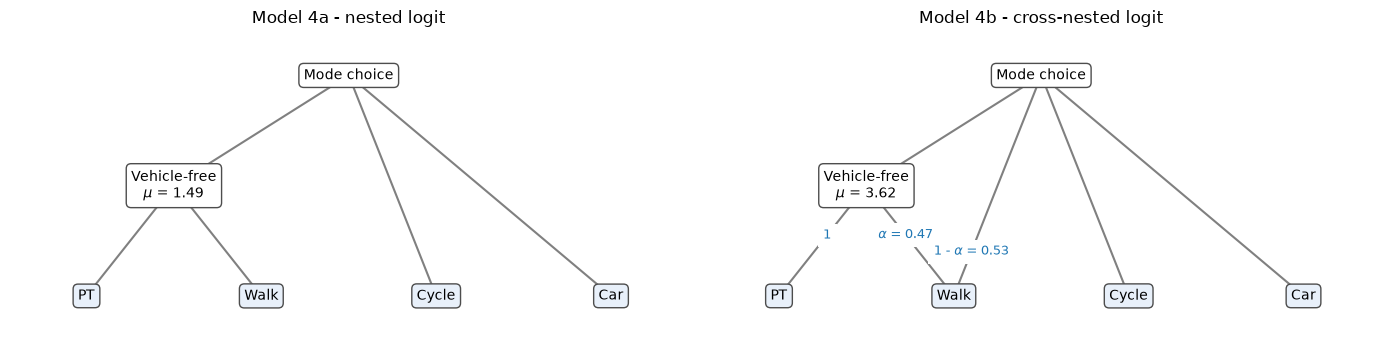

In [24]:
# Graphs of the two structures.
def draw_tree(ax, title, nest_label, nest_edges, root_edges):
    """nest_edges / root_edges: {alternative: edge label} linked to the nest / directly to the root."""
    x_alt = {'PT': 0.0, 'Walk': 1.6, 'Cycle': 3.2, 'Car': 4.8}
    root, nest = (2.4, 2.0), (0.8, 1.0)
    box = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='0.3')

    def edge(start, alternative, label, t):
        end = (x_alt[alternative], 0.0)
        ax.plot([start[0], end[0]], [start[1], end[1]], color='0.5', zorder=1)
        if label:
            ax.text(start[0] + t * (end[0] - start[0]), start[1] + t * (end[1] - start[1]), label, fontsize=9,
                    color='tab:blue', ha='center', va='center', bbox=dict(facecolor='white', edgecolor='none'))

    ax.plot([root[0], nest[0]], [root[1], nest[1]], color='0.5', zorder=1)
    for alternative, label in nest_edges.items():
        edge(nest, alternative, label, 0.45)
    for alternative, label in root_edges.items():
        edge(root, alternative, label, 0.8)
    ax.text(*root, 'Mode choice', ha='center', va='center', bbox=box)
    ax.text(*nest, nest_label, ha='center', va='center', bbox=box)
    for alternative, x in x_alt.items():
        ax.text(x, 0.0, alternative, ha='center', va='center', bbox=dict(box, facecolor='#e8f0fa'))
    ax.set_xlim(-0.7, 5.5)
    ax.set_ylim(-0.4, 2.4)
    ax.axis('off')
    ax.set_title(title)


beta_4a, beta_4b = results_4a.get_beta_values(), results_4b.get_beta_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
draw_tree(axes[0], 'Model 4a - nested logit', f"Vehicle-free\n$\\mu$ = {beta_4a['mu_vehicle_free']:.2f}",
          {'PT': None, 'Walk': None}, {'Cycle': None, 'Car': None})
draw_tree(axes[1], 'Model 4b - cross-nested logit', f"Vehicle-free\n$\\mu$ = {beta_4b['mu_vehicle_free_cnl']:.2f}",
          {'PT': '1', 'Walk': f"$\\alpha$ = {beta_4b['alpha_walk']:.2f}"},
          {'Walk': f"1 - $\\alpha$ = {1 - beta_4b['alpha_walk']:.2f}", 'Cycle': None, 'Car': None})
plt.tight_layout()
plt.show()

**Specification.** Both models keep the utilities of Model 3a. Only the error structure changes.

- **Model 4a (nested logit):** walking and PT are in a *vehicle-free* nest with scale parameter $\mu \ge 1$. Cycling and car are each alone. $G(y) = (y_{walk}^{\mu} + y_{pt}^{\mu})^{1/\mu} + y_{cycle} + y_{car}$.
- **Model 4b (cross-nested logit):** PT is in the vehicle-free nest. Walking belongs to it with allocation parameter $\alpha$ and to a nest of its own with $1-\alpha$. $G(y) = ((\alpha y_{walk})^{\mu} + y_{pt}^{\mu})^{1/\mu} + (1-\alpha) y_{walk} + y_{cycle} + y_{car}$.

**4.1. – Behavioral interpretation**  
- Explain the behavioral rationale for the proposed nestings.
  - Why are certain alternatives likely to share unobserved factors?
- How does this structure improve over $\text{Model}_\text{pref}$?

Walking and PT are the two modes that do not need a vehicle of one's own. Travellers without a car or bike at hand, or living in dense, well-served areas, share unobserved factors that make both modes attractive. Every PT trip also includes walking. The nest therefore makes walking and PT closer substitutes than the independence of irrelevant alternatives property of the multinomial logit model (Model 3a) allows. The cross-nested model additionally assumes that only part of walking competes with PT. The rest (very short trips, walking for leisure) is independent of PT.

**4.2. – Estimation and result interpretation**  
- Estimate both models:
  - Report parameter values, nest parameters (scale or allocation), and statistical significance.
  - Include null and final log-likelihoods.
- Discuss the estimated degree of correlation within and across nests.

In [25]:
all_results['model_4a_nested'] = results_4a
all_results['model_4b_cross_nested'] = results_4b
comparison_table, _ = compile_estimation_results(
    {name: all_results[name] for name in ['model_3a_log_time', 'model_4a_nested', 'model_4b_cross_nested']})
display(comparison_table)
print(f'Null log-likelihood (all models): {L0:.3f}')

,model_3a_log_time,model_4a_nested,model_4b_cross_nested
Number of estimated parameters,9,10,11
Sample size,5000,5000,5000
Final log likelihood,-4315.986,-4303.718,-4275.66
Akaike Information Criterion,8649.972,8627.436,8573.32
Bayesian Information Criterion,8708.627,8692.608,8645.009
b_time_walk (t-test),-12.3 (-27.1),-10.2 (-20),-10.1 (-20.9)
b_time_age (t-test),-1.03 (-9.11),-0.983 (-9.15),-0.985 (-9.29)
asc_cycle (t-test),-4.63 (-26.8),-4.21 (-24.7),-4.19 (-25.3)
b_time_cycle (t-test),-8.42 (-17.9),-8.11 (-17.8),-8.21 (-18.3)
asc_pt (t-test),-2.79 (-20.9),-2.05 (-12.3),-1.97 (-12.4)


Null log-likelihood (all models): -6931.472


- All utility parameters keep their sign and significance. The walking time coefficient and the PT and car constants become less negative (e.g. b_time_walk from −12.3 to −10.2, asc_pt from −2.79 to −2.05), as part of the difference between walking and PT is now captured by the nest.
- **Model 4a:** $\mu = 1.49$, significantly greater than 1 (t-test against 1: 4.00). This implies a positive correlation between the error terms of walking and PT.
- **Model 4b:** $\mu = 3.62$ (t-test against 1: 5.45) and $\alpha = 0.47$ (t-test against 1: −8.70). About half of walking shares a strong correlation with PT.
- **Fit:** the null LL is −6931.47. The final LL improves from −4315.99 (Model 3a) to −4303.72 (Model 4a) and −4275.66 (Model 4b). AIC and BIC are both lowest for Model 4b.

**4.3. – Model comparisons and updated Modelpref**  
- Use appropriate statistical tests to:
  - Compare $\text{Model}_\text{pref}$ with the nested model,
  - Compare the nested model with the cross-nested model,
- For each comparison:
  - State the null hypothesis,
  - Report the test statistic and degrees of freedom,
  - Justify which model to retain as the updated $\text{Model}_\text{pref}$.

In [26]:
# Nested models -> likelihood ratio tests (Model 3a = 4a with mu = 1; Model 4a = 4b with alpha_walk = 1).
for name, restricted, unrestricted in [('Model 3a vs 4a, H0: mu_vehicle_free = 1', results_3a, results_4a),
                                       ('Model 4a vs 4b, H0: alpha_walk = 1', results_4a, results_4b)]:
    lr = likelihood_ratio_test((restricted.final_loglikelihood, restricted.number_of_parameters),
                               (unrestricted.final_loglikelihood, unrestricted.number_of_parameters), 0.05)
    print(f'{name}: LR = {lr.statistic:.2f}, threshold = {lr.threshold:.2f} -> {lr.message}')

Model 3a vs 4a, H0: mu_vehicle_free = 1: LR = 24.54, threshold = 3.84 -> H0 can be rejected at level 5.0%
Model 4a vs 4b, H0: alpha_walk = 1: LR = 56.12, threshold = 3.84 -> H0 can be rejected at level 5.0%


The models are nested (Model 3a is Model 4a with $\mu = 1$; Model 4a is Model 4b with $\alpha = 1$), so LR tests are used. Both null hypotheses are rejected: the LR statistics are 24.54 and 56.12, against a threshold of 3.84 (1 degree of freedom). The restrictions lie on the bound of the parameter space, so these chi-square thresholds are conservative.

$\Rightarrow$ $\text{Model}_\text{pref}$ = **Model 4b**.

# Model 5 

---
Using the best model from Model 3 as a starting point, propose a **mixture model** that captures correlations across alternatives similar to the one modeled in the best nested structure of Model 4. Relax the independence of the error terms across alternatives. Estimate the model and report its structure and results.

1. State the behavioral assumption behind your proposed mixture specification. What type of correlation does it capture ?  

2. Comment on the estimation output (as defined previously).  

3. Compare the estimates of this model with the estimates from the best performing model from Model 4.



**5.0. – Model extension: relaxation of independence through mixtures**  
- Start from the best model obtained in Model 3.
- Propose a **mixture model** to relax the independence of error terms across alternatives.
- Your goal is to reproduce the best nested substitution patterns from Model 4, with a mixture model.
- Clearly specify the mixture structure and the utility function for each case.

**Specification.** Starting from Model 3a, an error component shared by walking and PT reproduces the vehicle-free nest:

$$U_{walk} = V_{walk}^{(3a)} + \sigma \xi + \varepsilon_{walk}, \quad U_{pt} = V_{pt}^{(3a)} + \sigma \xi + \varepsilon_{pt}, \quad U_{cycle} = V_{cycle}^{(3a)} + \varepsilon_{cycle}, \quad U_{car} = V_{car}^{(3a)} + \varepsilon_{car},$$

where $\xi$ follows a standard normal distribution and the $\varepsilon$ are i.i.d. EV (Gumbel) terms. Then $\text{corr}(U_{walk}, U_{pt}) = \sigma^2 / (\sigma^2 + \pi^2/6)$.

In [27]:
# Model 5: Model 3a + an error component shared by walk and PT, xi ~ N(0, 1).
# Monte Carlo integration with 1000 MLHS antithetic draws and a fixed seed.
NUMBER_OF_DRAWS = 1000
RANDOM_SEED = 1234
sigma_vehicle_free = Beta('sigma_vehicle_free', 1, None, None, 0)
xi_vehicle_free = Draws('xi_vehicle_free', 'NORMAL_MLHS_ANTI')

V_5 = {
    1: V_3a[1] + sigma_vehicle_free * xi_vehicle_free,
    2: V_3a[2],
    3: V_3a[3] + sigma_vehicle_free * xi_vehicle_free,
    4: V_3a[4],
}
results_5 = estimate_from_3a(log(MonteCarlo(logit(V_5, availability, travel_mode))), 'model_5_mixture',
                             number_of_draws=NUMBER_OF_DRAWS, seed=RANDOM_SEED, analytical_hessian_mode='automatic')

The number of draws (1000) is low. The results may not be meaningful.


**5.1. – Behavioral interpretation**  
- Explain the behavioral assumption underlying the use of a mixture.
  - What types of substitution patterns or unobserved heterogeneity does this model capture?
  - How does this differ from the assumptions in Model 4?

$\xi$ represents unobserved traveller characteristics that make walking and PT jointly more or less attractive (vehicle availability, place of residence, attitudes). It creates a positive correlation between the two modes, which relaxes the independence of irrelevant alternatives property as in Model 4. Unlike the nested and cross-nested logit models, the correlation comes from an explicit random term. The probabilities must be simulated, and one normal error component cannot reproduce the partial allocation of walking in Model 4b.

**5.2. – Estimation and output analysis**  
- Estimate the model using the transformed specification.
- Report:
  - Parameter estimates,
  - Statistical significance,
  - Null and final log-likelihoods.

In [28]:
# Store your estimated Model 5 result before comparing models.
all_results['model_5_mixture'] = results_5
print(results_5.short_summary())
display(get_pandas_estimated_parameters(estimation_results=results_5)['Estimated parameters'])
print(f'Null log-likelihood: {L0:.3f}')

Results for model model_5_mixture
Nbr of parameters:		10
Sample size:			5000
Excluded data:			0
Final log likelihood:		-4309.319
Akaike Information Criterion:	8638.637
Bayesian Information Criterion:	8703.809



,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,b_time_walk,-13.904238,0.739781,-18.795074,0.000000e+00
1,b_time_age,-1.263800,0.154660,-8.171481,2.220446e-16
2,sigma_vehicle_free,1.240311,0.230941,5.370678,7.844105e-08
3,asc_cycle,-4.978321,0.216589,-22.985115,0.000000e+00
4,b_time_cycle,-10.177838,0.761625,-13.363325,0.000000e+00
5,asc_pt,-2.986592,0.164622,-18.142129,0.000000e+00
6,b_time_pt,-7.410116,0.667487,-11.101507,0.000000e+00
7,b_cost,-0.162987,0.015296,-10.655298,0.000000e+00
8,asc_car,-2.742663,0.186355,-14.717414,0.000000e+00
9,b_time_car,-10.893927,0.780314,-13.960956,0.000000e+00


Null log-likelihood: -6931.472


$\sigma = 1.24$ (t-test: 5.37) is significant, so the error terms of walking and PT are positively correlated. All other parameters keep their sign and significance. They are larger in absolute value than in Model 3a because the scale changes. The final LL is −4309.32 (null LL: −6931.47). That is better than Model 3a (−4315.99) but worse than Models 4a (−4303.72) and 4b (−4275.66).

**5.3. - Compare the estimates with those from the Model 4**
- Compare with an appropriate method the estimates of this model with the estimates from Model 4.

In [29]:
# Raw coefficients are on different scales (different error variances), so we compare ratios to the cost
# coefficient (in GBP) and the implied correlation between the walk and PT error terms.
beta_5 = results_5.get_beta_values()
compare = pd.DataFrame({
    model: {name: values[name] / values['b_cost'] for name in
            ['b_time_walk', 'b_time_cycle', 'b_time_pt', 'b_time_car', 'b_time_age', 'asc_cycle', 'asc_pt', 'asc_car']}
    for model, values in [('Model 4b', beta_4b), ('Model 5', beta_5)]
})
compare.loc['final log-likelihood'] = [results_4b.final_loglikelihood, results_5.final_loglikelihood]
display(compare.round(2))
sigma2 = beta_5['sigma_vehicle_free'] ** 2
print(f'corr(walk, pt): Model 5 = {sigma2 / (sigma2 + np.pi ** 2 / 6):.3f}, '
      f"vehicle-free nest of Model 4a = {1 - 1 / beta_4a['mu_vehicle_free'] ** 2:.3f}")

,Model 4b,Model 5
b_time_walk,69.53,85.31
b_time_cycle,56.69,62.45
b_time_pt,43.34,45.46
b_time_car,60.50,66.84
b_time_age,6.81,7.75
asc_cycle,28.95,30.54
asc_pt,13.63,18.32
asc_car,13.69,16.83
final log-likelihood,-4275.66,-4309.32


corr(walk, pt): Model 5 = 0.483, vehicle-free nest of Model 4a = 0.547


Raw coefficients cannot be compared because the scale differs, so the comparison uses ratios to the cost coefficient. The time trade-offs for cycling, PT and car, and the age effect, are similar in both models. The walking time trade-off and the PT and car constants are larger in the mixture. The implied correlation between walking and PT in the mixture (0.483) is of the same order as in the vehicle-free nest of Model 4a (0.547). The mixture captures the same correlation pattern, but fits worse than Model 4b (LL −4309.32 vs −4275.66).

<div class="alert alert-info">

 Denote this mixture model as **$\text{Model}_\text{pref}$**, and use it as the reference model for all remaining questions (Market Shares and Forecasting).  

</div>

# Market Shares 

---

Assume that stratified random sampling was used to produce your sample. We consider the following strata:

- S1: females aged 42 years or younger  
- S2: females aged 43 years or older  
- S3: males aged 42 years or younger  
- S4: males aged 43 years or older

The table below gives the size of each category in the full population:

|               | Age < 43     | Age ≥ 43    |
|---------------|--------------|-------------|
| **Male**      | 2,926,408    | 1,379,198   |
| **Female**    | 2,841,376    | 1,519,948   |

(Source: ONS, 2015)

---

In [30]:
# 6.1: Define the four strata, count the sample size in each one, and calculate a weight from the population and sample shares.
# Attach the appropriate stratum weight to every observation.
# 6.2: Simulate individual probabilities, multiply by the weights, then aggregate and normalize by the total weight.
# 6.3: For observed shares, group observations by observed choice, sum the weights, and normalize by the total weight.
modes = {1: 'walk', 2: 'cycle', 3: 'pt', 4: 'car'}
beta_pref = results_5.get_beta_values()
probabilities_pref = {name: MonteCarlo(logit(V_5, availability, alt)) for alt, name in modes.items()}


def make_simulator(data, formulas):
    return bio.BIOGEME(db.Database('simulation', data), formulas, number_of_draws=NUMBER_OF_DRAWS, seed=RANDOM_SEED)


def weighted_shares(probabilities):
    return probabilities[list(modes.values())].mul(df['weight'], axis=0).sum() / df['weight'].sum()

**6.1. – Compute stratum weights**  
- Based on your sample, compute the number of individuals in each stratum (S1–S4).
- Calculate the **weight** of each stratum.
$$
\omega_g = \frac{N_g}{N} \frac{S}{S_g}=\frac{\text{share of persons in
    segment $g$ in population}}{\text{share of persons in segment $g$ in sample}}
$$
- Report the size and weight of each stratum.  



In [31]:
strata = pd.DataFrame({'population': [2_841_376, 1_519_948, 2_926_408, 1_379_198]},
                      index=['S1 (F, <=42)', 'S2 (F, >=43)', 'S3 (M, <=42)', 'S4 (M, >=43)'])
df['stratum'] = np.select([(df['female'] == 1) & (df['age'] <= 42), (df['female'] == 1) & (df['age'] >= 43),
                           (df['female'] == 0) & (df['age'] <= 42), (df['female'] == 0) & (df['age'] >= 43)],
                          [0, 1, 2, 3])
strata['sample size'] = df['stratum'].value_counts().sort_index().values
strata['weight'] = (strata['population'] / strata['population'].sum()) / (strata['sample size'] / len(df))
df['weight'] = strata['weight'].values[df['stratum']]
display(strata.round(4))

,population,sample size,weight
"S1 (F, <=42)",2841376,117,14.0103
"S2 (F, >=43)",1519948,133,6.5930
"S3 (M, <=42)",2926408,2350,0.7184
"S4 (M, >=43)",1379198,2400,0.3315


Women are strongly under-represented in the sample compared with the population, so their weights are large (14.01 and 6.59). Men are under-weighted (0.72 and 0.33).

**6.2. – Predict weighted market shares using Modelpref**  

- Use $\text{Model}_\text{pref}$ and the stratum weights to compute the **predicted market share** of each transport mode.
- Also compute **confidence intervals** for the predicted shares.
- Comment: Do the results match your expectations?  

<div class="alert alert-warning">

  <strong>Warning:</strong>\
   Depending on your machine, it might take too long to use bootstrapping for confidence intervals.
  If it's the case, you can use ```use_bootstrap=False```, in ```get_betas_for_sensitivity_analysis``` to disable bootstrapping.\
  The disadvantage is that it relies on the assumption that the estimates follow a normal distribution.
</div>

In [32]:
simulator = make_simulator(df, probabilities_pref)
predicted_shares = weighted_shares(simulator.simulate(beta_pref))

# 95% confidence intervals: shares simulated for 100 draws of the parameters (asymptotic normal distribution;
# bootstrapping would require re-estimating the mixture 100 times).
share_draws = pd.DataFrame([weighted_shares(simulator.simulate(b))
                            for b in results_5.get_betas_for_sensitivity_analysis(size=100, use_bootstrap=False)])
market_shares = pd.DataFrame({'predicted': predicted_shares, 'CI 2.5%': share_draws.quantile(0.025),
                              'CI 97.5%': share_draws.quantile(0.975)})
display((100 * market_shares).round(2))

The number of draws (1000) is low. The results may not be meaningful.


,predicted,CI 2.5%,CI 97.5%
walk,19.23,18.30,20.15
cycle,4.65,4.10,5.33
pt,33.36,32.22,34.47
car,42.77,41.31,44.19


Predicted shares: walking 19.23%, cycling 4.65%, PT 33.36%, car 42.77%, with narrow confidence intervals. As expected for London, car and PT dominate and cycling is marginal.

**6.3. – Compare with weighted observed shares**  

- Compute the actual weighted market shares in your sample (using the actual observed choices and stratum weights).
- Compare these to the model-predicted shares.  

In [33]:
market_shares['observed'] = df.groupby('travel_mode')['weight'].sum().rename(modes) / df['weight'].sum()
display((100 * market_shares).round(2))

,predicted,CI 2.5%,CI 97.5%,observed
walk,19.23,18.30,20.15,19.40
cycle,4.65,4.10,5.33,3.59
pt,33.36,32.22,34.47,36.37
car,42.77,41.31,44.19,40.64


Walking is well reproduced. Cycling and car are overpredicted, and PT is underpredicted (observed 36.37% vs predicted 33.36%). A likely cause is that gender, which defines the strata, is not in the model: women's trips have large weights, so any difference in their behaviour that the model does not capture shows up in the weighted shares.

# Forecasting 

---

Consider the following scenarios:

1. An additional charge of £1.5 for car users  
2. A 20% decrease in public transport cost

---

In [34]:
# 7.1: Start from a baseline simulation; change only the attribute affected by each scenario, then simulate and aggregate weighted shares again.
# 7.2: Compare the weighted car shares from the baseline and scenarios.
# 7.3: For each scenario, combine the PT probability, scenario fare, and observation weight before aggregating revenue.
# 7.4: Obtain marginal utilities of time and cost, form their ratio with consistent units, then calculate weighted averages.
# 7.5: Calculate individual probabilities and derivatives, form direct/cross elasticities, then aggregate them with the appropriate weights.
df_scenario_1 = df.assign(total_driving_cost=df['total_driving_cost'] + 1.5)  # +1.5 GBP for car users
df_scenario_2 = df.assign(cost_transit=0.8 * df['cost_transit'])              # -20% PT cost
scenarios = {'baseline': df, 'scenario 1': df_scenario_1, 'scenario 2': df_scenario_2}
scenario_probabilities = {name: make_simulator(data, probabilities_pref).simulate(beta_pref)
                          for name, data in scenarios.items()}

The number of draws (1000) is low. The results may not be meaningful.
The number of draws (1000) is low. The results may not be meaningful.
The number of draws (1000) is low. The results may not be meaningful.


**7.1. – Simulate market shares under policy scenarios**  

- Use $\text{Model}_\text{pref}$ to predict the market shares for each of the two policy scenarios:
  - Scenario 1: increase the cost of car by £1.5
  - Scenario 2: decrease the cost of public transport by 20%
- Compare the predicted market shares to the original (baseline) shares.
- Comment: Do the results match your expectations?  


In [35]:
scenario_shares = pd.DataFrame({name: weighted_shares(p) for name, p in scenario_probabilities.items()})
scenario_shares['change 1 (p.p.)'] = scenario_shares['scenario 1'] - scenario_shares['baseline']
scenario_shares['change 2 (p.p.)'] = scenario_shares['scenario 2'] - scenario_shares['baseline']
display((100 * scenario_shares).round(2))

,baseline,scenario 1,scenario 2,change 1 (p.p.),change 2 (p.p.)
walk,19.23,20.32,19.08,1.09,-0.15
cycle,4.65,5.24,4.55,0.60,-0.10
pt,33.36,35.69,34.24,2.33,0.88
car,42.77,38.74,42.13,-4.02,-0.64


The results match expectations. Making the car more expensive moves trips to all other modes, mostly PT (+2.33 percentage points). Cheaper PT attracts trips from all other modes, mostly from car.

**7.2. – Policy evaluation: car reduction**  

- Which scenario is more effective at **reducing the market share of car**?
- Justify your answer based on the model results.  

**Scenario 1** is more effective: the car share falls by 4.02 percentage points, against 0.64 for scenario 2. It acts directly on the car utility, and £1.5 is large compared with typical driving costs (median £0.71). A cheaper PT fare only affects car users through substitution.

**7.3. – Revenue analysis**  

- Compute the **total revenue** from public transport under each scenario.
- Identify which scenario yields the highest revenue.
- Compare with the revenue in the original situation.
- Provide an explanation for the result.  

In [36]:
revenue = pd.Series({name: (df['weight'] * scenario_probabilities[name]['pt'] * data['cost_transit']).sum()
                     for name, data in scenarios.items()}, name='PT revenue, weighted sample (GBP)')
display(pd.DataFrame({'PT revenue, weighted sample (GBP)': revenue, 'change (%)': 100 * (revenue / revenue['baseline'] - 1)}).round(1))

,"PT revenue, weighted sample (GBP)",change (%)
baseline,3922.0,0.0
scenario 1,4158.7,6.0
scenario 2,3238.4,-17.4


**Scenario 1** gives the highest revenue (+6.0%): more PT trips at unchanged fares. Scenario 2 reduces revenue by 17.4%. The PT share only rises from 33.36% to 34.24%, which does not compensate for the 20% lower fare.

**7.4. – Value of time**  

- Compute the **average value of time** (VOT) for car and for public transport.
- Report the results and comment on them.  

In [37]:
# VOT = (dV/dtime) / (dV/dcost) in GBP/hour (times in hours). The error component does not affect the
# derivatives, so the deterministic utilities of Model 3a are used with the parameters of Model 5.
vot_formulas = {
    'PT': Derive(V_3a[3], 'total_pt_duration') / Derive(V_3a[3], 'cost_transit'),
    'car': Derive(V_3a[4], 'dur_driving') / Derive(V_3a[4], 'total_driving_cost'),
}
vot = make_simulator(df, vot_formulas).simulate({k: v for k, v in beta_pref.items() if k != 'sigma_vehicle_free'})
display(vot.mul(df['weight'], axis=0).sum().div(df['weight'].sum()).rename('average VOT (GBP/h)').round(2).to_frame())

,average VOT (GBP/h)
PT,29.91
car,50.92


The average value of time is £29.91/h for PT and £50.92/h for car. Car time is valued more because driving requires attention and involves congestion, while time in PT can partly be used for other activities. With the logarithmic time specification and the age interaction, the value of time is higher for short trips and for older travellers.

**7.5. – Elasticity analysis**  

- Compute the following **aggregate elasticities**:
  - **Direct elasticities**:
    - Car cost $\rightarrow$ car choice
    - PT cost $\rightarrow$ PT choice
  - **Cross elasticities**:
    - Car cost $\rightarrow$ PT, Cycle and Walk
    - PT cost $\rightarrow$ Car, Cycle and Walk
- A total of 8 values must be reported.
- Comment on the signs and magnitudes of the elasticities.  

In [38]:
# Aggregate elasticity of mode i: sum_n w_n P_n(i) E_n(i) / sum_n w_n P_n(i), with the disaggregate point
# elasticity E_n(i) = dP_n(i)/dx_n * x_n / P_n(i). The normalization factor is sum_n w_n P_n(i).
formulas = dict(probabilities_pref)
for name in modes.values():
    for attribute, variable in [('car cost', total_driving_cost), ('PT cost', cost_transit)]:
        formulas[f'{name} | {attribute}'] = (Derive(probabilities_pref[name], variable.name) * variable
                                             / probabilities_pref[name])
simulated = make_simulator(df, formulas).simulate(beta_pref)

normalization = {name: (df['weight'] * simulated[name]).sum() for name in modes.values()}
elasticities = pd.DataFrame([
    {'attribute': attribute, 'mode': name,
     'elasticity': (df['weight'] * simulated[name] * simulated[f'{name} | {attribute}']).sum() / normalization[name],
     'normalization factor': normalization[name]}
    for attribute in ['car cost', 'PT cost'] for name in ['car', 'pt', 'cycle', 'walk']
]).set_index(['attribute', 'mode'])
display(elasticities.round(4))

The number of draws (1000) is low. The results may not be meaningful.


elasticity  normalization factor
attribute mode                                   
car cost  car       -0.0845             2138.2536
          pt         0.0798             1667.9697
          cycle      0.1237              232.3292
          walk       0.0196              961.4474
PT cost   car        0.0746             2138.2536
          pt        -0.1321             1667.9697
          cycle      0.1035              232.3292
          walk       0.0383              961.4474

Direct elasticities are negative and cross elasticities positive, as expected. All are far below 1 in absolute value, so demand is very inelastic to cost, especially for car. Cross elasticities are largest for cycling and smallest for walking. The normalization factors $\sum_n w_n P_n(i)$ are reported in the table.